In [1]:
import numpy as np
import os
import sys
module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)

from common.helper import *
import matplotlib.pyplot as plt
from mini_shap.independent_tree_shap import IndependentTreeExplainer
import pandas as pd
from tree.xg_classifier import XGClassifier
from xgboost import XGBClassifier
import shap

/home/sakane/Documents/projects/python/mini_xgshap/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
X_train, X_test, y_train, y_test, scale_pos_weight = load_data_and_scale_pos_weight(cast_string=True)
X_train_np, X_test_np, y_train_np, y_test_np = X_train.to_numpy().astype(np.float32), X_test.to_numpy().astype(np.float32), y_train.to_numpy().astype(np.float32), y_test.to_numpy().astype(np.float32)

In [3]:
m1 = XGBClassifier()
m1.load_model('../model/prauc_model2.ubj')
m2 = XGClassifier.load_from_xgbclassifier(m1, columns=list(X_train.columns))

In [4]:
pred_raw1 = m1.predict(X_test, output_margin=True)
pred_proba1 = m1.predict_proba(X_test)
y_pred = m1.predict(X_test)

In [5]:
expv, sv = load_shap_values("shap_values.npy")

In [6]:
mask = np.isclose(pred_raw1, expv + sv.sum(1), rtol=0.0, atol=1e-4)
mask.sum() == len(pred_raw1)

np.True_

In [7]:
explanation = shap.Explanation(
    values=sv,
    base_values=expv,
    data=X_test_np,
    feature_names=X_train.columns,
)

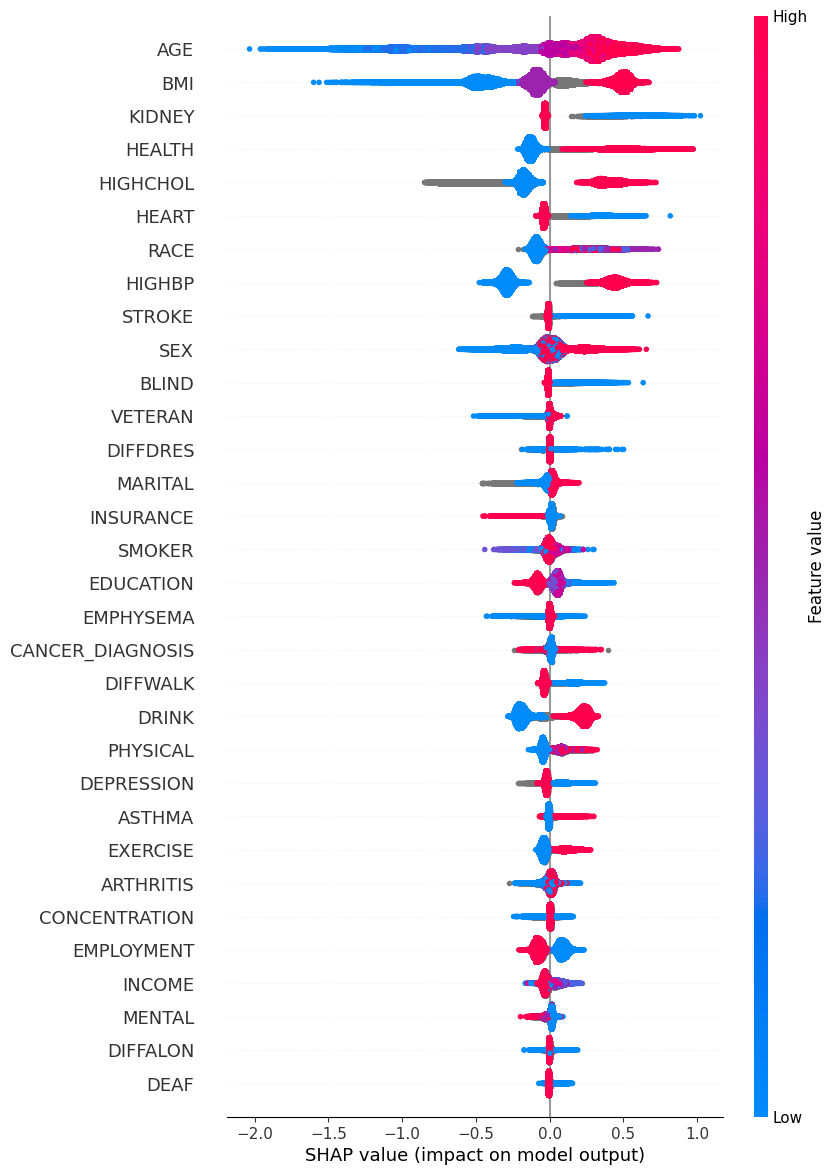

In [8]:
shap.plots.beeswarm(explanation, order=explanation.abs.max(0), max_display=33)

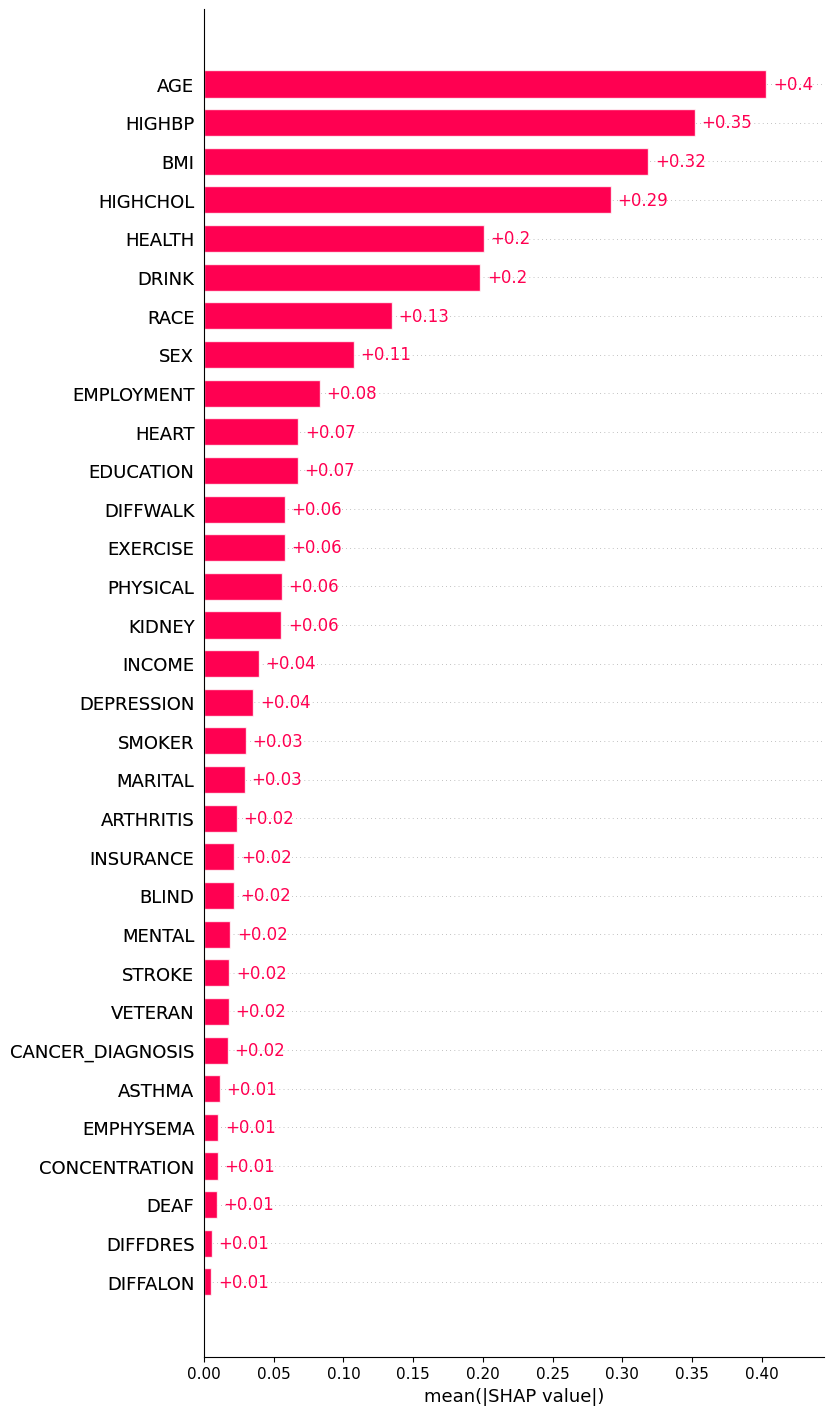

In [9]:
shap.plots.bar(explanation, max_display=33)

In [10]:
pred_proba1[:, 1]

array([0.03639171, 0.1060966 , 0.6068213 , ..., 0.30891612, 0.05217765,
       0.52660114], shape=(347338,), dtype=float32)

In [11]:
new_index = [i for i in range(len(X_test))]
X_test = X_test.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

In [12]:
X_test.reset_index(drop=True)

,SEX,INCOME,ARTHRITIS,EMPHYSEMA,DEPRESSION,KIDNEY,HIGHBP,HIGHCHOL,DRINK,INSURANCE,...,DIFFWALK,DIFFDRES,DIFFALON,HEART,STROKE,ASTHMA,SMOKER,EXERCISE,VETERAN,CANCER_DIAGNOSIS
0,0,2,1,1,1,1,0,NaN,1,0,...,1,1,1,1,1,0,3,0,1,0
1,0,4,1,1,1,1,0,0,0,1,...,1,1,1,1,1,0,3,0,1,0
2,1,4,0,1,1,1,1,1,0,NaN,...,0,1,1,1,1,0,3,0,1,1
3,1,NaN,1,1,1,0,0,NaN,1,0,...,1,1,1,1,1,NaN,3,0,1,0
4,1,4,1,1,1,1,0,0,0,0,...,1,1,1,1,1,0,3,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
347333,1,3,1,1,1,1,1,1,0,NaN,...,1,1,1,1,1,0,3,0,1,1
347334,1,0,0,1,0,1,1,1,1,NaN,...,0,0,1,1,1,0,2,1,1,0
347335,0,4,0,1,1,1,0,0,0,NaN,...,1,1,1,1,1,0,2,0,0,1
347336,0,4,1,1,1,1,0,0,0,0,...,1,1,1,1,1,0,3,0,1,0


In [13]:
# True positive high confidence
tp = X_test[(y_test == 1) & (y_pred == 1) & (pred_proba1[:, 1] >= 0.9)].sample(1)

# True negative high confidence  
tn = X_test[(y_test == 0) & (y_pred == 0) & (pred_proba1[:, 1] <= 0.1)].sample(1)

# False negative
fn = X_test[(y_test == 1) & (y_pred == 0)].sample(1)

# Optional false positive
fp = X_test[(y_test == 0) & (y_pred == 1)].sample(1)

** True Positive **

In [14]:
tp.T

,247122
SEX,1
INCOME,4
ARTHRITIS,1
EMPHYSEMA,1
DEPRESSION,0
KIDNEY,1
HIGHBP,1
HIGHCHOL,1
DRINK,1
INSURANCE,NaN


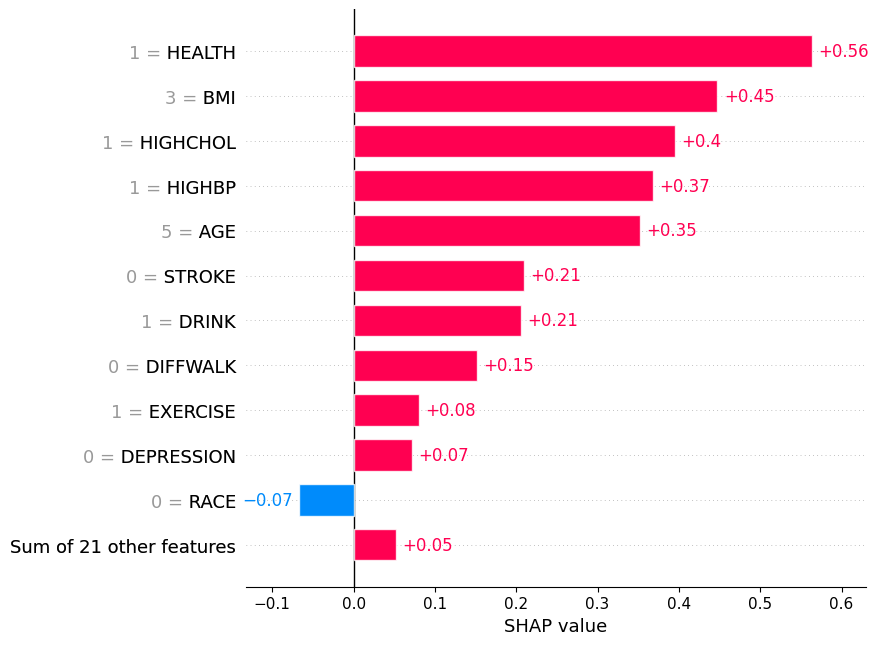

In [15]:
shap.plots.bar(explanation[tp.iloc[0].name], max_display=12)

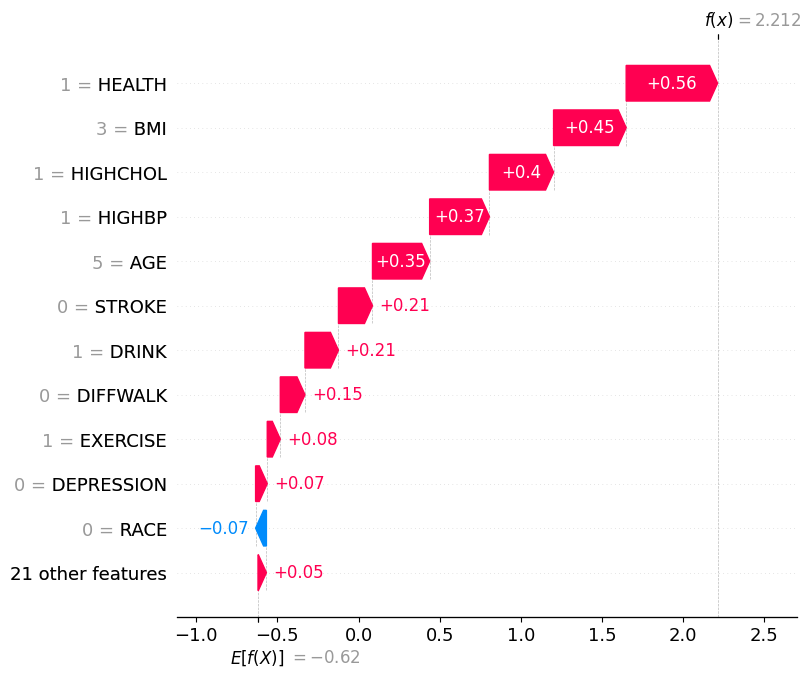

In [16]:
shap.plots.waterfall(explanation[tp.iloc[0].name], max_display=12)

** True Negative **

In [17]:
tn.T

,142837
SEX,0
INCOME,4
ARTHRITIS,1
EMPHYSEMA,1
DEPRESSION,1
KIDNEY,1
HIGHBP,0
HIGHCHOL,0
DRINK,1
INSURANCE,0


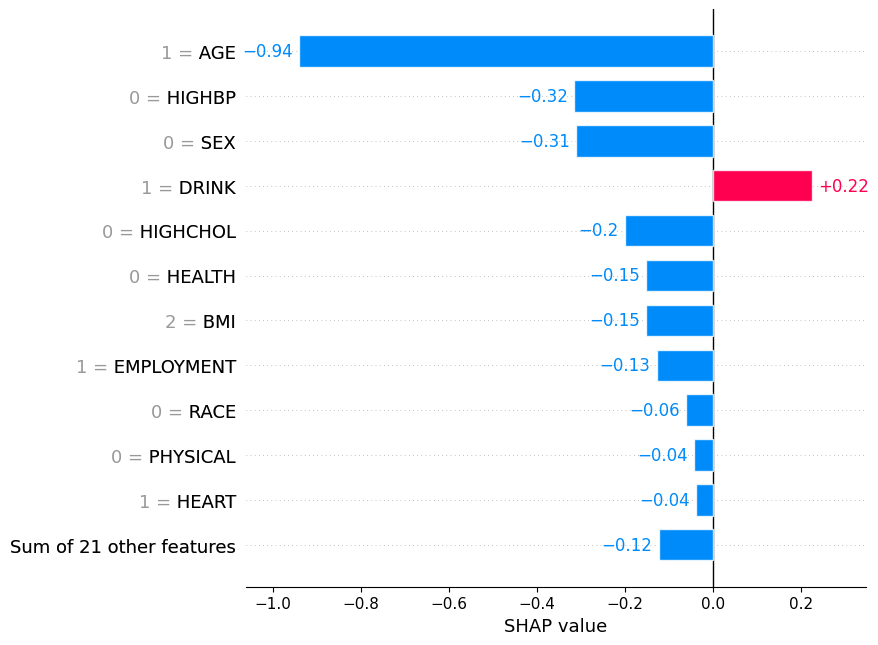

In [18]:
shap.plots.bar(explanation[tn.iloc[0].name], max_display=12)

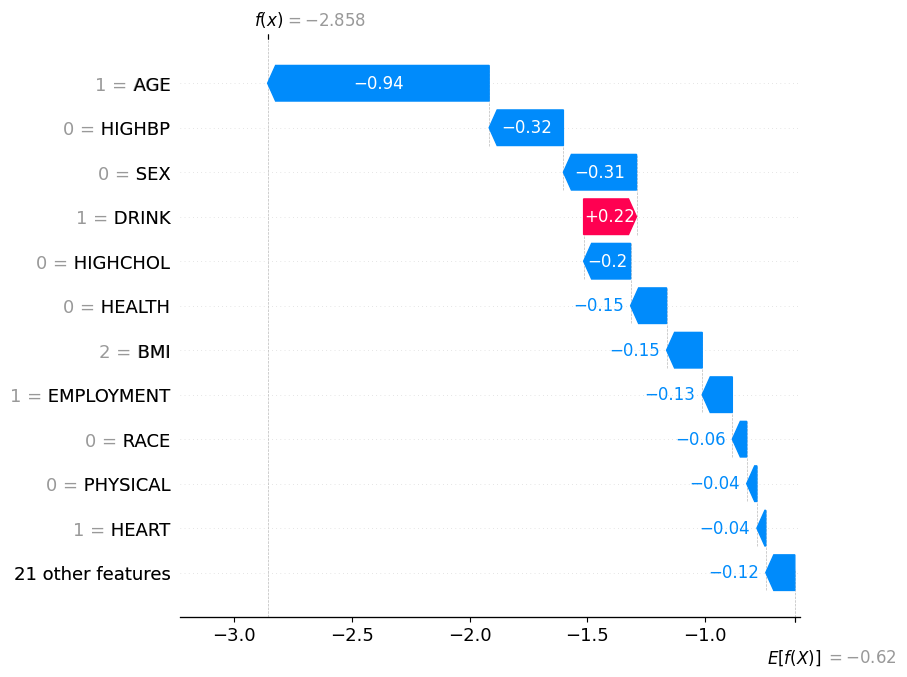

In [19]:
shap.plots.waterfall(explanation[tn.iloc[0].name], max_display=12)

** False Negative **

In [20]:
fn.T

,204163
SEX,1
INCOME,4
ARTHRITIS,1
EMPHYSEMA,1
DEPRESSION,0
KIDNEY,1
HIGHBP,1
HIGHCHOL,0
DRINK,0
INSURANCE,0


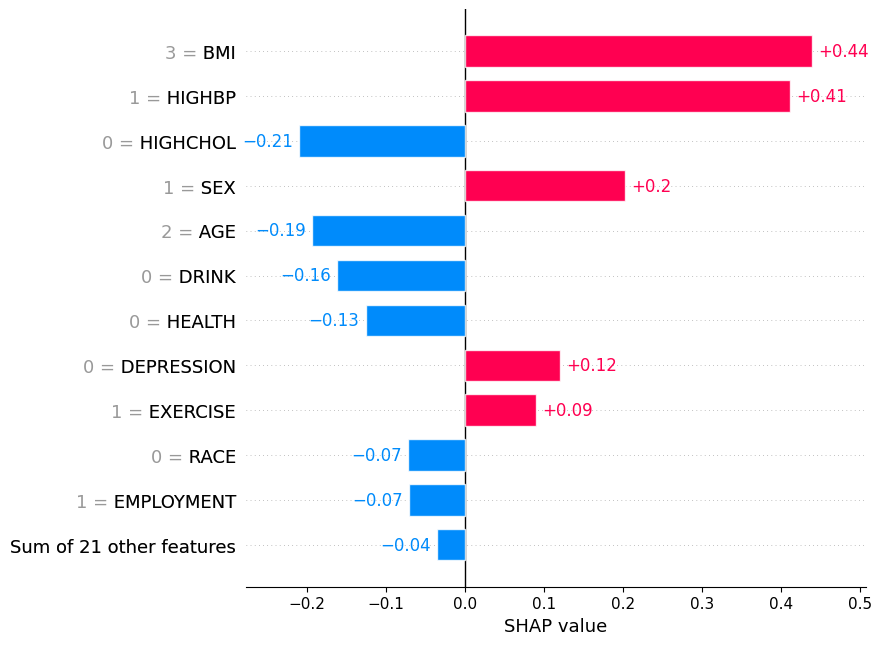

In [21]:
shap.plots.bar(explanation[fn.iloc[0].name], max_display=12)

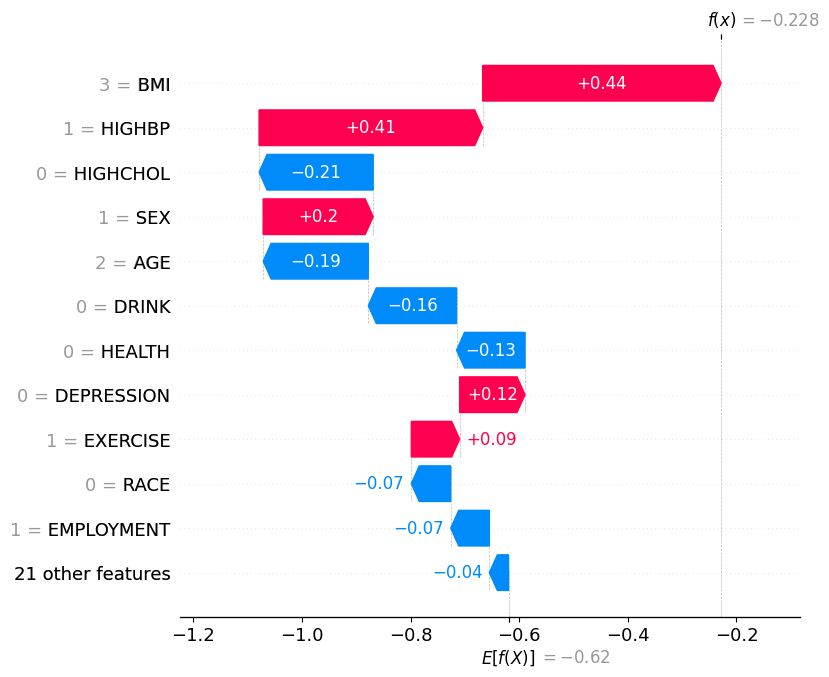

In [22]:
shap.plots.waterfall(explanation[fn.iloc[0].name], max_display=12)

** False Positive **

In [23]:
fp.T

,319128
SEX,0
INCOME,4
ARTHRITIS,0
EMPHYSEMA,1
DEPRESSION,1
KIDNEY,1
HIGHBP,0
HIGHCHOL,0
DRINK,1
INSURANCE,NaN


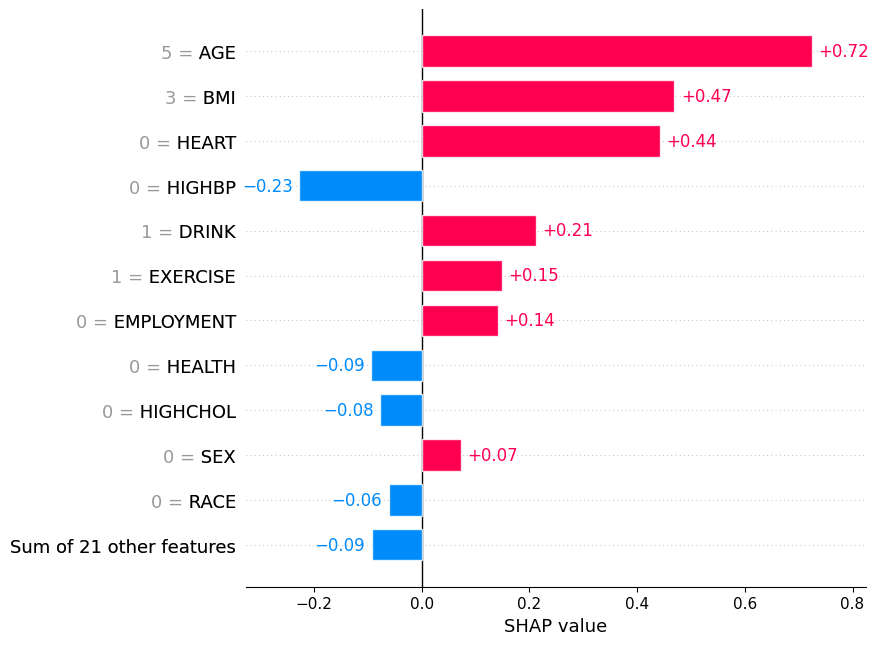

In [24]:
shap.plots.bar(explanation[fp.iloc[0].name], max_display=12)

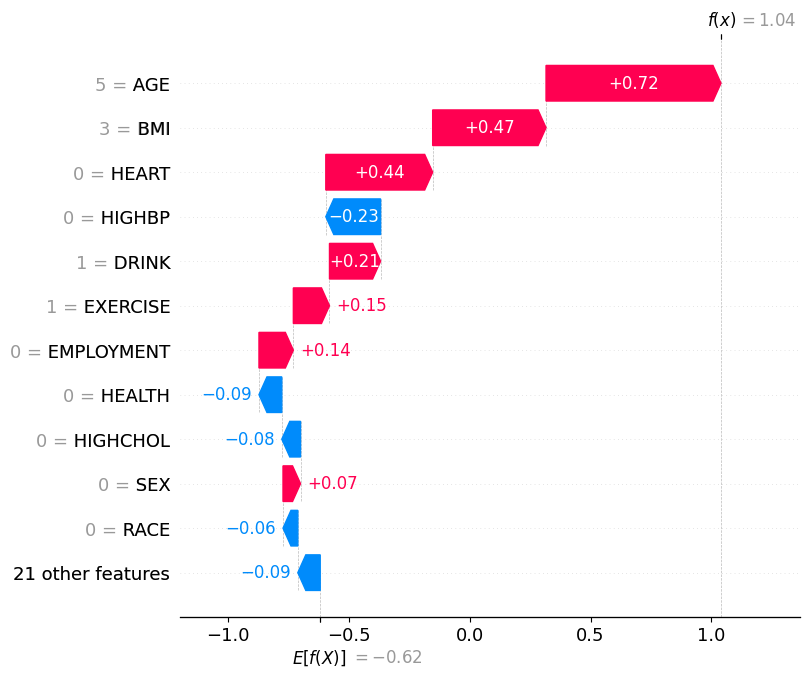

In [25]:
shap.plots.waterfall(explanation[fp.iloc[0].name], max_display=12)